In [1]:
import sys
import os
from astropy.io import fits
import pandas as pd

# ====================================================================
# 1. ENLAZAR EL DIRECTORIO EXTERNO
# ====================================================================
ruta_directorio_clase = "MAIN_CODE/" 

if ruta_directorio_clase not in sys.path:
    sys.path.append(ruta_directorio_clase)

# ====================================================================
# 2. IMPORTAR LA CLASE
# ====================================================================
from Morphology_analysis import MorphologyAnalyzer


In [2]:

# ====================================================================
# 3. INSTANCIAR LA CLASE
# ====================================================================
print("Inicializando el analizador morfológico...")
analizador = MorphologyAnalyzer()

Inicializando el analizador morfológico...


In [3]:
# Sacar la informacion del CSV
ruta_info_fits = "/path/to/your/data/objects_info/Targets_Info.csv"
print("Cargando información de los objetos desde el CSV...")
data_info = pd.read_csv(ruta_info_fits, sep='\s+')
print(data_info.head())  # Mostrar las primeras filas para verificar la carga


Cargando información de los objetos desde el CSV...
   OB_GTC       ID  redshift           RA          DEC
0       1  WISE248    0.4511  21:51:24.18  -05:30:59.8
1       2  WISE177    0.6110  21:15:25.48   05:59:18.5
2       3  WISE124    0.3380  07:35:42.52   65:27:31.9
3       4  WISE130    0.2660  07:37:25.60   65:43:02.6
4       5  WISE173    0.0920  08:06:46.38   15:30:12.9


<>:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_5498/1988012932.py:4: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  data_info = pd.read_csv(ruta_info_fits, sep='\s+')


In [ ]:
import numpy as np
from astropy.io import fits
import os

# ====================================================================
# 4. EJECUTAR EL MÉTODO DE SEGMENTACIÓN CON RECORTE FÍSICO (INLINE)
# ====================================================================
# Definimos los datos de prueba y rutas
mi_imagen_fits = "test/data_test/GTC69-25B_OB0001_r.fits"
mi_directorio_salida = "test/data_test/"

# File data
RA = data_info.loc[0, 'RA']  # RA de la galaxia (en grados)
DEC = data_info.loc[0, 'DEC']  # DEC de la galaxia (en grados)
REDSHIFT = data_info.loc[0, 'redshift']  # Redshift de la galaxia

# Nos aseguramos de que el directorio de salida exista
os.makedirs(mi_directorio_salida, exist_ok=True)

# --------------------------------------------------------------------
# Parámetros físicos del objeto y del instrumento
# --------------------------------------------------------------------
ra_agn = RA         # <-- Pon aquí la RA real de tu galaxia
dec_agn = DEC          # <-- Pon aquí la DEC real de tu galaxia
redshift_agn = REDSHIFT       # <-- Redshift (z) del objeto
radio_recorte_kpc = 60.0  # <-- Radio del recorte en kpc
pixel_scale_gtc = 0.254   # Escala de placa para GTC (arcsec/px)

try:
    # Abrimos el archivo FITS para extraer los datos y la cabecera (header)
    with fits.open(mi_imagen_fits) as hdul:
        if hdul[0].data is not None:
            image_data = hdul[0].data
            header = hdul[0].header
        else:
            image_data = hdul[1].data
            header = hdul[1].header
            
    # ====================================================================
    # PROCESO DE RECORTE DIRECTO USANDO TUS FUNCIONES EXISTENTES
    # ====================================================================
    # 1. Buscamos el centro geométrico (x, y) de la galaxia en píxeles
    px, py = analizador.radec_to_pixel(header, ra_agn, dec_agn)
    center_x, center_y = int(np.round(px)), int(np.round(py))
    
    # 2. Traducimos los kpc a píxeles usando tu función physical_to_pixels
    # NOTA: Tu función espera parsecs (pc), por eso multiplicamos los kpc por 1000
    pixel_size_val = analizador.physical_to_pixels(
        size_pc=radio_recorte_kpc * 1000, 
        redshift=redshift_agn, 
        pixel_scale_arcsec=pixel_scale_gtc
    )
    crop_radius = round(int(np.ceil(pixel_size_val))) - 1
    
    # 3. Calculamos los límites de la caja asegurando no salirnos de la imagen
    y_min = max(0, center_y - crop_radius)
    y_max = min(image_data.shape[0], center_y + crop_radius)
    x_min = max(0, center_x - crop_radius)
    x_max = min(image_data.shape[1], center_x + crop_radius)
    
    # 4. Cortamos la matriz para obtener la imagen pequeña centrada
    imagen_recortada = image_data[y_min:y_max, x_min:x_max]
    # ====================================================================

    # Si el recorte se ejecutó correctamente, procedemos a la segmentación
    if imagen_recortada is not None and imagen_recortada.size > 0:
        
        # Llamamos a tu función de segmentación pasando la IMAGEN RECORTADA
        resultados_segmentacion = analizador.SegmentationMap(
            image=imagen_recortada,  
            hot_snr=30.0,    
            cold_snr=2.0
        )

        # Si todo ha ido bien y no ha devuelto 'None'
        if resultados_segmentacion is not None:
            print("\n--- ¡Análisis completado! ---")
            
            imagen_limpia = resultados_segmentacion['imagen_limpia']
            mapa_de_ruido = resultados_segmentacion['ruido_mapa']
            mascara_total = resultados_segmentacion['segmask_total']
            mapa_final = resultados_segmentacion['segmap_final']
            
            print(f"El mapa de segmentación detectó {len(mapa_final.labels)} objetos distintos.")
            
            # Graficamos los resultados en el panel 2x2
            analizador.plot_segmentation_results(
                seg_results=resultados_segmentacion, 
                obj_id=f"GTC69-25B (z={redshift_agn}, R={radio_recorte_kpc}kpc)" 
            )

except FileNotFoundError:
    print(f"Error: No se ha encontrado el archivo en la ruta {mi_imagen_fits}")
except Exception as e:
    print(f"Ha ocurrido un error inesperado: {e}")


 ======= Processing morphology for WISE248 ======= 

 [Crop] Calculando recorte para 40.0 kpc a z=0.4511...
 [Crop] Centro del AGN (x,y): (1946, 1214)
 [Crop] Radio de recorte: 26 píxeles.
  Crop radius: 26 pixels (from 40.0 kpc at z=0.4511)
 [SegmentationMap] Preparando imagen y máscaras iniciales...
 [SegmentationMap] Estimando fondo del cielo iterativamente...
 [SegmentationMap] Generando mapa de segmentación (Hot-Cold)...


 [SegmentationMap] ¡Segmentación completada con éxito!


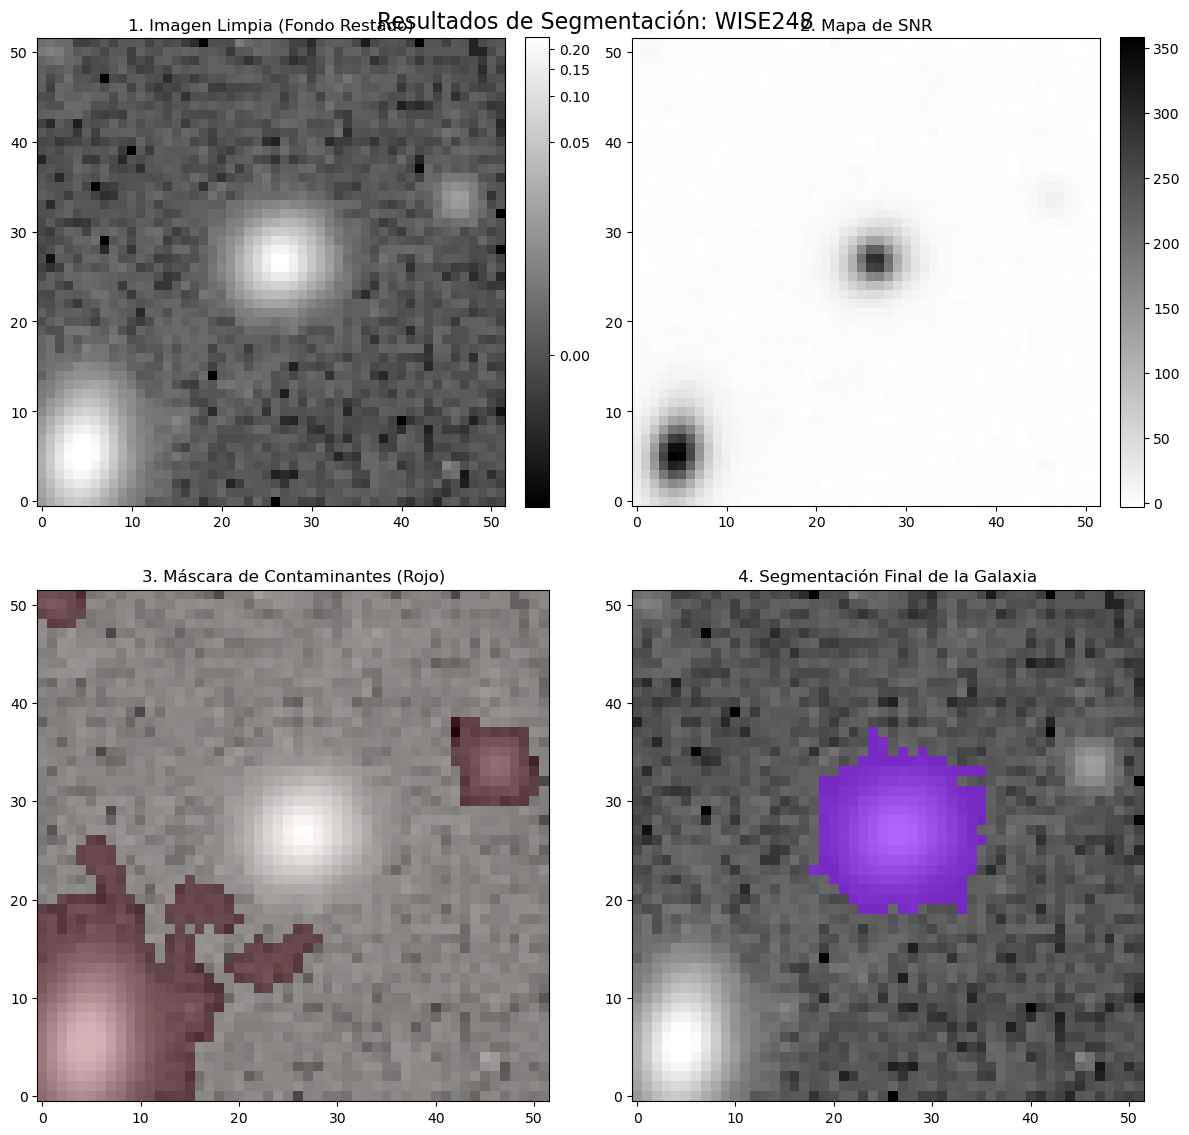


  No weightmap provided. Running statmorph with detector gain...
  Isophote asymmetry values: [np.float64(0.5613298425382289), np.float64(0.3078431160241262), np.float64(0.09932208633561482), np.float64(0.11374927127899503), np.float64(0.12398462519149724)]


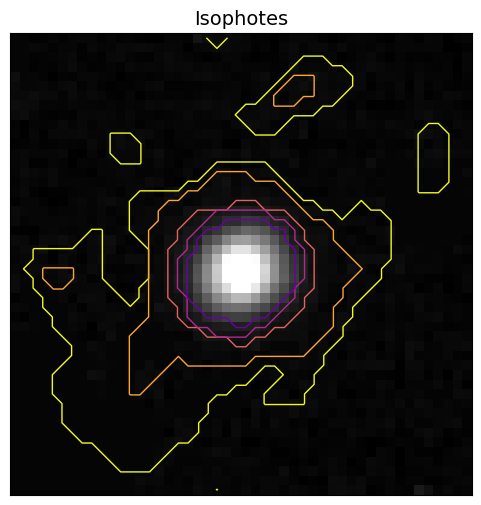

  Statmorph running time: 0.723368 s.
  Saved Shape Asymmetry plot to test/data_test/Analyzed/A_s_Figs/AS_OBJ_WISE248.png 

  Morphology parameters calculated successfully.
{'Object_ID': 'WISE248', 'Redshift': np.float64(0.4511), 'Concentration (C)': np.float64(2.5135118420374942), 'Asymmetry (A)': np.float64(0.028775913491743473), 'Smoothness (S)': np.float64(0.0), 'Shape_Asymmetry (A_s)': np.float64(0.16510909680904623), 'Gini': np.float64(0.46826286491696373), 'M20': np.float64(-1.6388503471289064)}


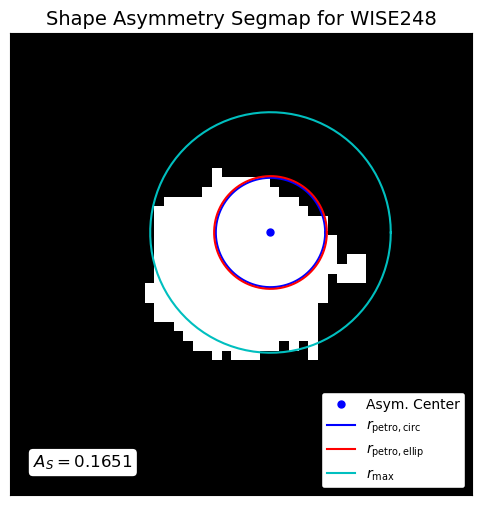

In [5]:
# Example Morphology Parameter Calculation
results = analizador.calculate_morphology_parameters(
    obj_id=data_info.loc[0, 'ID'],         # ID of the object
    file_path=mi_imagen_fits,              # We compute the morphology on the unsharp masked image
    ra=data_info.loc[0, 'RA'],             # RA of the object
    dec=data_info.loc[0, 'DEC'],           # DEC of the object
    redshift=data_info.loc[0, 'redshift'], # redshift of the object
    size_kpc=40.0,                         # size of the image to analyze in kpc
    gain=1.0,                              # gain of the instrument
    output_dir_base=mi_directorio_salida   # base output directory
)

# Imprimir los resultados rápidamente
print(results)